# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**
- Dataset name: Marketing Campaign Performance Dataset
- Source + URL: Kaggle, https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset
- Why I chose it: 6 channels to compare, a daily date column (many rows per channel), and all the inputs for CPA, ROAS and conversion rate
- What is one row? One campaign on one date; after cleaning, one channel on one day

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [6]:
import kagglehub, glob
path = kagglehub.dataset_download("manishabhatt22/marketing-campaign-performance-dataset")
CSV_PATH = glob.glob(f"{path}/*.csv")[0]
COLUMN_MAP = {"Date": "date", "Channel_Used": "channel", "Impressions": "impressions",
              "Clicks": "clicks", "Acquisition_Cost": "cost"}

raw = pd.read_csv(CSV_PATH).rename(columns=COLUMN_MAP)
print(raw.shape)
print(raw.dtypes)
raw.head()

/opt/miniconda3/envs/bootcamp-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(200000, 16)
Campaign_ID           int64
Company                 str
Campaign_Type           str
Target_Audience         str
Duration                str
channel                 str
Conversion_Rate     float64
cost                    str
ROI                 float64
Location                str
Language                str
clicks                int64
impressions           int64
Engagement_Score      int64
Customer_Segment        str
date                    str
dtype: object


,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,channel,Conversion_Rate,cost,ROI,Location,Language,clicks,impressions,Engagement_Score,Customer_Segment,date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [7]:
df = raw.copy()
num_cols = ["impressions", "clicks", "conversions", "cost", "revenue"]

# 1. Types + derived columns
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["cost"] = pd.to_numeric(df["cost"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
df["conversions"] = (df["Conversion_Rate"] * df["clicks"]).round()
df["revenue"] = df["cost"] * (1 + df["ROI"])          # ROI = (revenue - cost) / cost

# 2. Missing values and impossible rows
print(df[["date", "channel"] + num_cols].isna().sum())
df = df.dropna(subset=["date", "channel"] + num_cols).drop_duplicates()
ok = ((df[["impressions", "clicks", "conversions", "cost"]] >= 0).all(axis=1)
      & (df.clicks <= df.impressions) & (df.conversions <= df.clicks))
print(f"Removed {(~ok).sum()} impossible rows")
df = df[ok]

# Aggregate campaigns to one row per channel per day
df = df.groupby(["date", "channel"], as_index=False)[num_cols].sum()

# 3. Summary
print(df.channel.nunique(), "channels")
print(df.channel.value_counts())
print("From", df.date.min().date(), "to", df.date.max().date())

# 4. Save
df.to_csv(OUT / "marketing_data.csv", index=False)

date           0
channel        0
impressions    0
clicks         0
conversions    0
cost           0
revenue        0
dtype: int64
Removed 0 impossible rows
6 channels
channel
Email         365
Facebook      365
Google Ads    365
Instagram     365
Website       365
YouTube       365
Name: count, dtype: int64
From 2021-01-01 to 2021-12-31


**✍️ Transformations I made:** 
- Renamed columns to the standard names (date, channel, impressions, clicks, cost)
- Parsed `cost` from text ("$12,500.00") to a number
- Derived `conversions` = Conversion_Rate × clicks (rounded), and `revenue` = cost × (1 + ROI)
- Checked missing values (none) and impossible rows (0 removed)
- Aggregated ~200,000 campaign rows to one row per channel per day: 6 channels × 365 days (2021)
- Saved to outputs/marketing_data.csv

💡 **Think:** how many rows does each channel have? That number is your **N** for the t-tests later.

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [8]:
agg = df.groupby("channel")[num_cols].sum()
agg["CTR"] = agg.clicks / agg.impressions
agg["conv_rate"] = agg.conversions / agg.clicks
agg["CPA"] = (agg.cost / agg.conversions).where(agg.cost > 0)
agg["ROAS"] = (agg.revenue / agg.cost).where(agg.cost > 0)
agg["profit"] = agg.revenue - agg.cost
agg["profit_margin"] = agg.profit / agg.revenue
agg = agg.replace([np.inf, -np.inf], np.nan)
agg.round(4)

,impressions,clicks,conversions,cost,revenue,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
Email,184801107,18493963,1485425.0,420874104.0,2.524644e+09,0.1001,0.0803,283.3358,5.9986,2.103770e+09,0.8333
Facebook,180659428,18037947,1446338.0,410595258.0,2.474541e+09,0.0998,0.0802,283.8861,6.0267,2.063945e+09,0.8341
Google Ads,185006879,18340807,1468717.0,418912314.0,2.516724e+09,0.0991,0.0801,285.2233,6.0078,2.097811e+09,0.8335
Instagram,183738455,18316654,1462938.0,417124850.0,2.497101e+09,0.0997,0.0799,285.1282,5.9865,2.079977e+09,0.8330
Website,183806353,18414628,1477660.0,416593500.0,2.504152e+09,0.1002,0.0802,281.9278,6.0110,2.087559e+09,0.8336
YouTube,183448082,18350407,1463649.0,416778582.0,2.501105e+09,0.1000,0.0798,284.7531,6.0010,2.084326e+09,0.8334


💡 **Hint: watch out for zero-cost channels** (e.g. SEO, organic). ROAS becomes infinite, and CPA becomes **$0**, which would make the channel look like the best one. Use `.where(agg.cost > 0)` to give them no CPA.

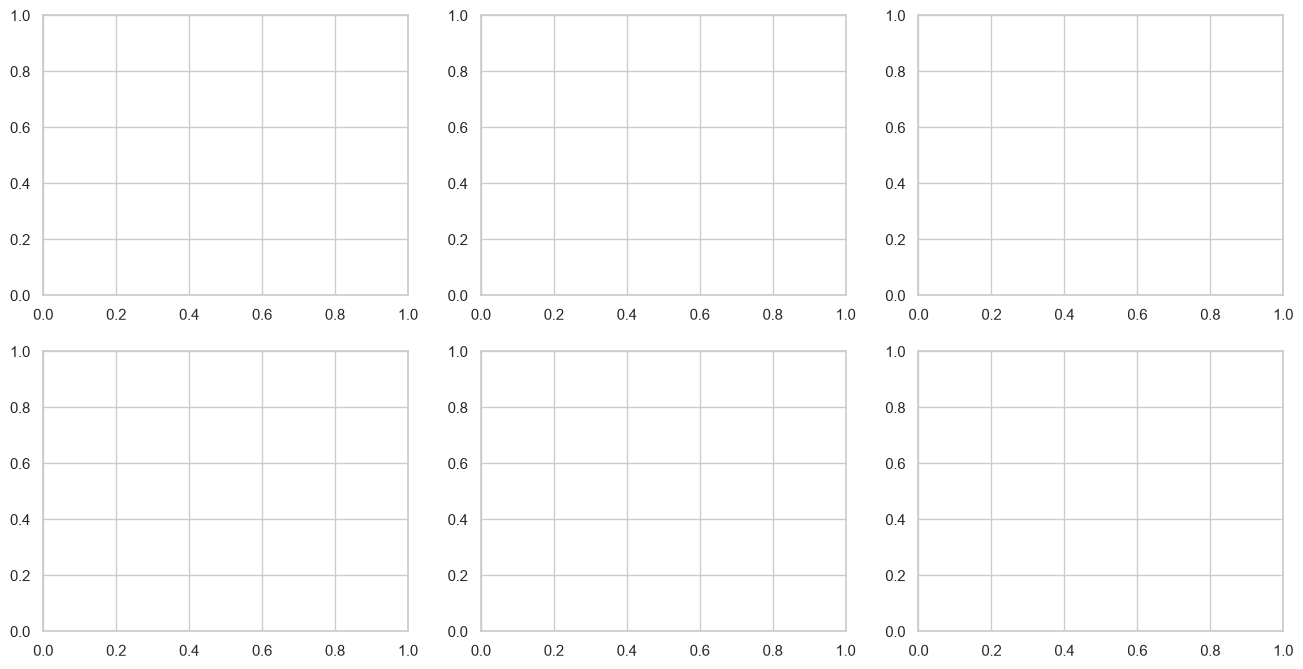

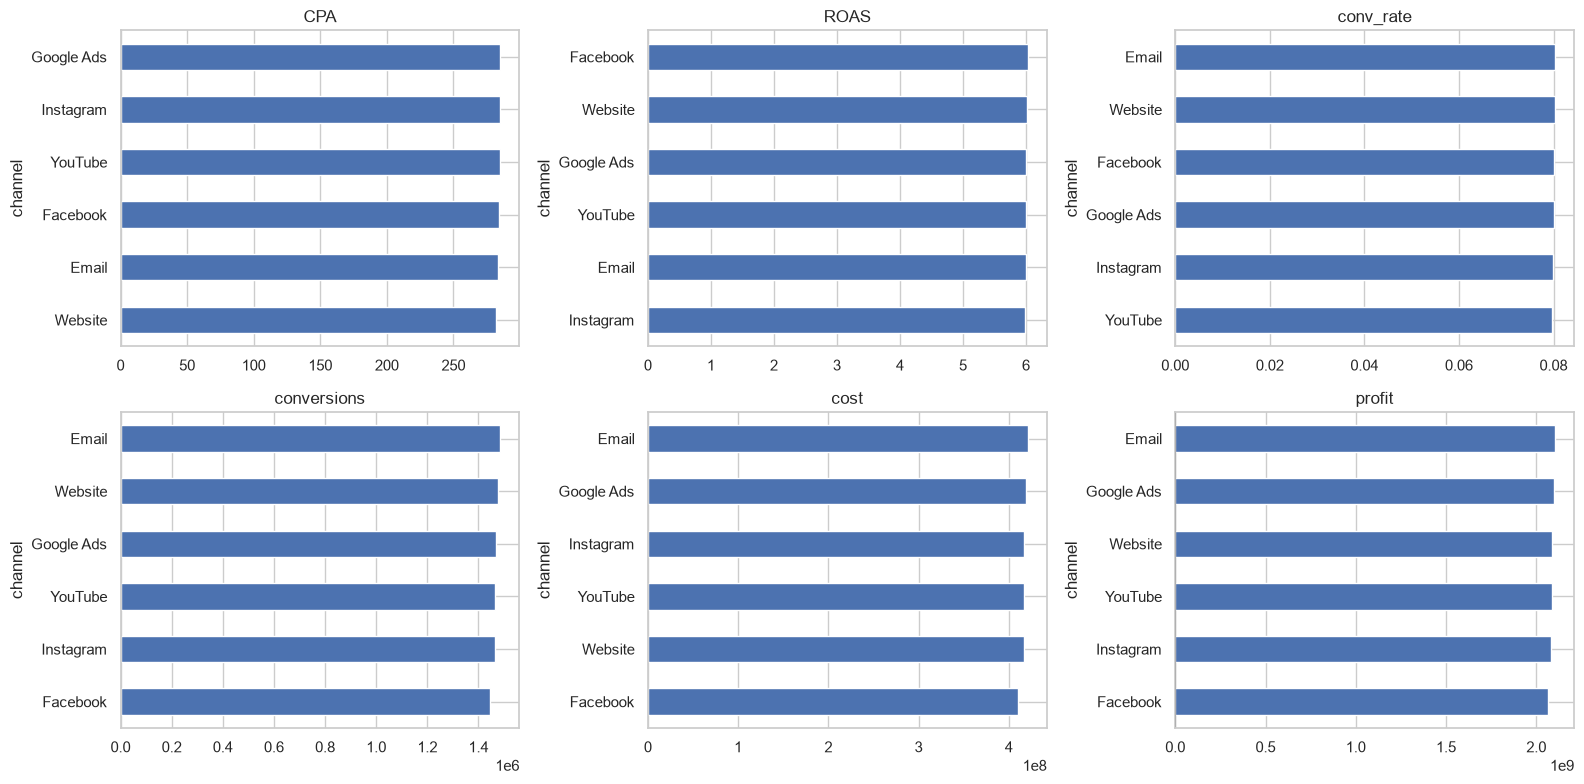

<Figure size 640x480 with 0 Axes>

In [9]:
# TODO: 2x3 grid of horizontal bar charts: CPA, ROAS, conversion rate, conversions, cost, profit
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["CPA", "ROAS", "conv_rate", "conversions", "cost", "profit"]):
    agg[col].sort_values().plot.barh(ax=ax, title=col)
    if col == "profit":
        ax.axvline(0, color="black")
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()
# Profit chart: add a vertical line at 0 (ax.axvline(0, color="black"))
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()

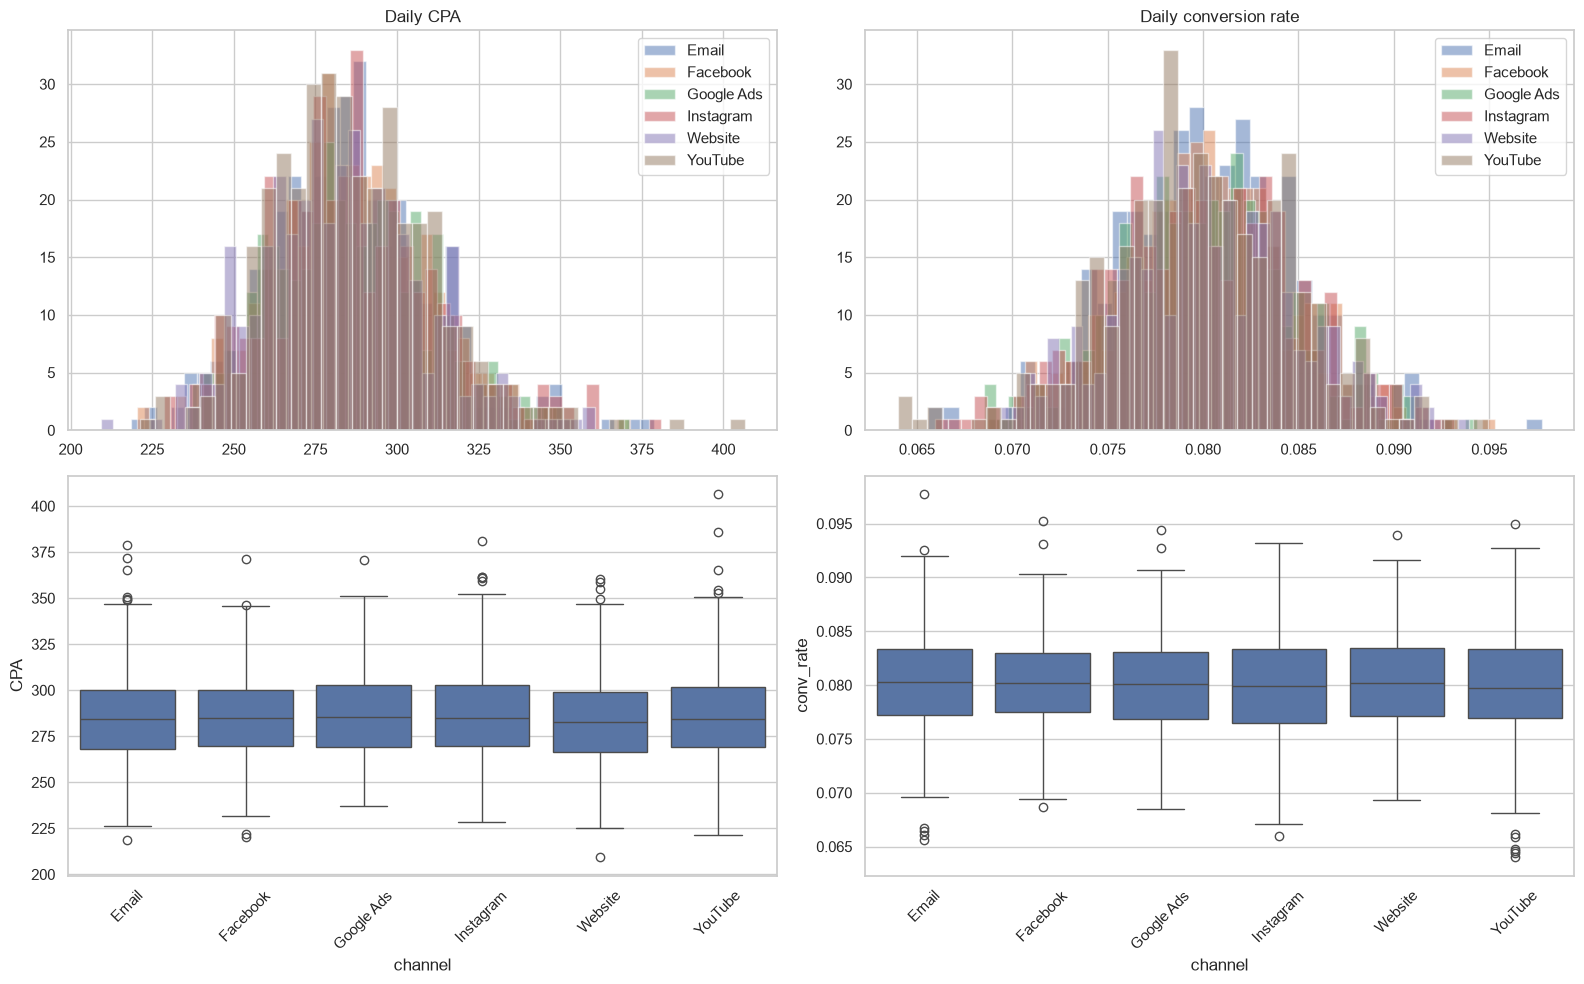

,mean,std,CV
channel,,,
Facebook,285.565,23.313,0.082
Google Ads,286.800,23.990,0.084
Website,283.615,24.255,0.086
Email,285.070,24.704,0.087
YouTube,286.442,25.276,0.088
Instagram,286.926,26.016,0.091


In [10]:
df["CPA"] = (df.cost / df.conversions).where(df.cost > 0)
df["conv_rate"] = df.conversions / df.clicks
df["ROAS"] = (df.revenue / df.cost).where(df.cost > 0)    # needed in Part 5
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ch, sub in paid.groupby("channel"):
    axes[0, 0].hist(sub.CPA.dropna(), bins=40, alpha=0.5, label=ch)
    axes[0, 1].hist(sub.conv_rate.dropna(), bins=40, alpha=0.5, label=ch)
axes[0, 0].set_title("Daily CPA"); axes[0, 0].legend()
axes[0, 1].set_title("Daily conversion rate"); axes[0, 1].legend()
sns.boxplot(data=paid, x="channel", y="CPA", ax=axes[1, 0])
sns.boxplot(data=paid, x="channel", y="conv_rate", ax=axes[1, 1])
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=120)
plt.show()

variability = paid.groupby("channel").CPA.agg(["mean", "std"])
variability["CV"] = variability["std"] / variability["mean"]
display(variability.sort_values("CV").round(3))

**✍️ Key insights:** best channel on each metric? Most variable channel? Outliers? Which channels look **close**?

💡 **Remember (§1–2 of the statistics notebook):** each channel's CPA is an **estimate** from a sample of days, not a fact.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [11]:
def cohens_d(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

def effect_label(d):
    d = abs(d)
    return "negligible" if d < 0.2 else "small" if d < 0.5 else "medium" if d < 0.8 else "large"

def pairwise_ttests(data, metric):
    clean = data[["channel", metric]].replace([np.inf, -np.inf], np.nan).dropna()
    clean = clean[clean[metric] > 0]
    rows = []
    for a, b in combinations(sorted(clean.channel.unique()), 2):
        xa = clean.loc[clean.channel == a, metric]
        xb = clean.loc[clean.channel == b, metric]
        t, p = stats.ttest_ind(xb, xa, equal_var=False)
        diff = xb.mean() - xa.mean()
        d = cohens_d(xa, xb)
        rows.append({"group_a": a, "group_b": b, "mean_a": xa.mean(), "mean_b": xb.mean(),
                     "diff": diff, "pct_diff": diff / xa.mean() * 100, "t_stat": t, "p_value": p,
                     "cohens_d": d, "effect": effect_label(d), "significant": p < ALPHA})
    res = pd.DataFrame(rows)
    print(f"{metric}: {len(res)} comparisons, {res.significant.sum()} significant")
    return res

cpa_res = pairwise_ttests(paid, "CPA")
cvr_t_res = pairwise_ttests(df, "conv_rate")

CPA: 15 comparisons, 0 significant
conv_rate: 15 comparisons, 0 significant


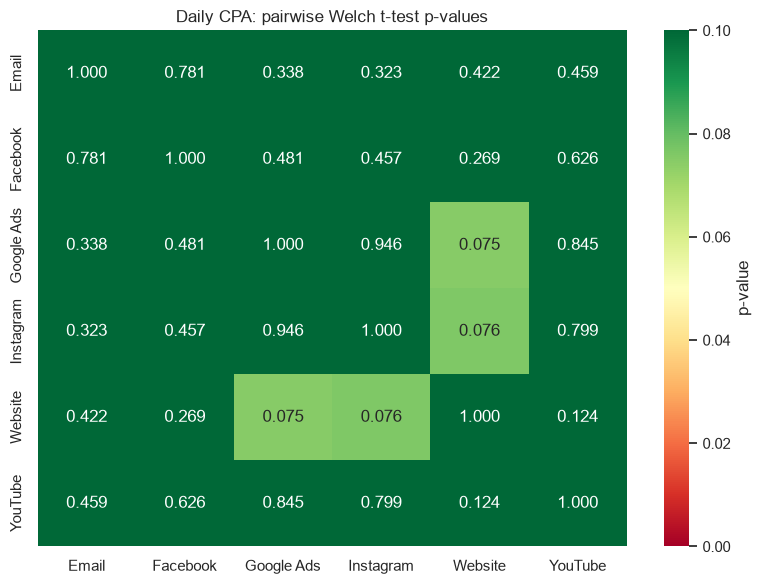

In [12]:
chs = sorted(set(cpa_res.group_a) | set(cpa_res.group_b))
pmat = pd.DataFrame(1.0, index=chs, columns=chs)
for _, r in cpa_res.iterrows():
    pmat.loc[r.group_a, r.group_b] = pmat.loc[r.group_b, r.group_a] = r.p_value

plt.figure(figsize=(8, 6))
sns.heatmap(pmat, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=0.1,
            cbar_kws={"label": "p-value"})
plt.title("Daily CPA: pairwise Welch t-test p-values")
plt.tight_layout()
plt.savefig(OUT / "metric_comparison_heatmap.png", dpi=120)
plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?**

No channel pair differs significantly in daily CPA (0 of 15 Welch t-tests at α = 0.05), and the same holds for daily conversion rate (0 of 15). The closest pairs are Website vs Google Ads (p = 0.075) and Website vs Instagram (p = 0.076): Website has the lowest daily CPA (~$283.6) and the other two the highest (~$286.8–286.9), a gap of about 1.1%. Even that gap is only about 0.13 standard deviations (negligible Cohen's d), small next to normal day-to-day variation.
A high p-value means we **can't tell the channels apart** with 365 days of data, not that they are proven identical. Part 4 checks whether we'd have enough data to detect a gap of this size.

💡 **Remember (§3):** a big p-value means **"can't tell"**, not "no difference".

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [13]:
conv = df.groupby("channel")[["conversions", "clicks"]].sum().astype(int)
conv["non_conversions"] = conv.clicks - conv.conversions
conv["conv_rate"] = conv.conversions / conv.clicks

rows = []
for a, b in combinations(sorted(conv.index), 2):
    table = [[conv.loc[a, "conversions"], conv.loc[a, "non_conversions"]],
             [conv.loc[b, "conversions"], conv.loc[b, "non_conversions"]]]
    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    ra, rb = conv.loc[a, "conv_rate"], conv.loc[b, "conv_rate"]
    rows.append({"group_a": a, "group_b": b, "rate_a": ra, "rate_b": rb,
                 "diff_pp": (rb - ra) * 100, "pct_diff": (rb - ra) / ra * 100,
                 "odds_ratio": odds_ratio, "p_value": p, "significant": p < ALPHA})
fisher_res = pd.DataFrame(rows)
print(f"Fisher: {len(fisher_res)} comparisons, {fisher_res.significant.sum()} significant")
display(conv)

Fisher: 15 comparisons, 9 significant


,conversions,clicks,non_conversions,conv_rate
channel,,,,
Email,1485425,18493963,17008538,0.080319
Facebook,1446338,18037947,16591609,0.080183
Google Ads,1468717,18340807,16872090,0.080079
Instagram,1462938,18316654,16853716,0.079869
Website,1477660,18414628,16936968,0.080244
YouTube,1463649,18350407,16886758,0.079761


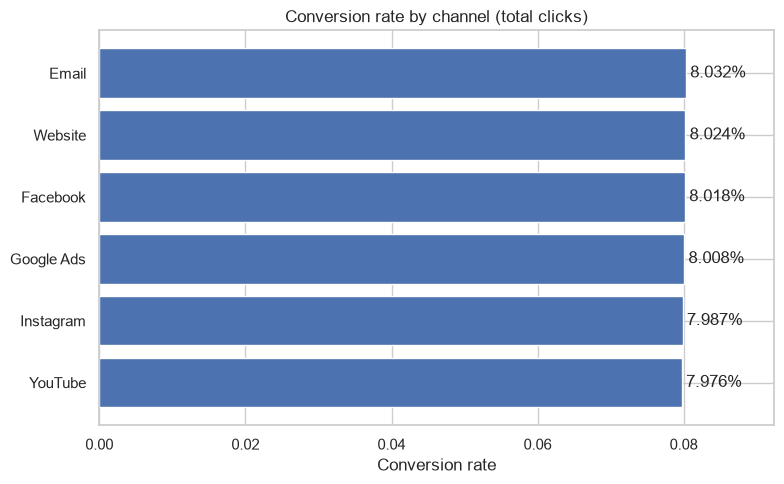

9 of 15 pairs disagree between Fisher and the t-test


,group_a,group_b,diff_pp,significant_fisher,significant_ttest
1,Email,Google Ads,-0.0240,True,False
2,Email,Instagram,-0.0450,True,False
4,Email,YouTube,-0.0558,True,False
6,Facebook,Instagram,-0.0314,True,False
8,Facebook,YouTube,-0.0422,True,False
9,Google Ads,Instagram,-0.0210,True,False
11,Google Ads,YouTube,-0.0318,True,False
12,Instagram,Website,0.0375,True,False
14,Website,YouTube,-0.0483,True,False


In [14]:
rates = conv.conv_rate.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rates.index, rates.values)
ax.bar_label(bars, labels=[f"{v:.3%}" for v in rates.values], padding=3)
ax.set_xlabel("Conversion rate"); ax.set_title("Conversion rate by channel (total clicks)")
ax.set_xlim(0, rates.max() * 1.15)
plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=120)
plt.show()

cmp = fisher_res[["group_a", "group_b", "diff_pp", "significant"]].merge(
    cvr_t_res[["group_a", "group_b", "significant"]], on=["group_a", "group_b"],
    suffixes=("_fisher", "_ttest"))
disagree = cmp[cmp.significant_fisher != cmp.significant_ttest]
print(f"{len(disagree)} of {len(cmp)} pairs disagree between Fisher and the t-test")
display(disagree.round(4))

**✍️ Answer:**
1. **Which channels differ significantly?** Fisher's exact test flags 9 of 15 pairs (α = 0.05, before correction). The significant pairs mostly involve the top group (Email 8.032%, Website 8.024%, Facebook 8.018%) against the bottom group (Instagram 7.987%, YouTube 7.976%). [list the 9 pairs from the table]

2. **Large enough to matter?** No. The largest gap, Email vs YouTube, is 0.056 percentage points: about 1 extra conversion per 1,800 clicks, or ~0.7% relative. That is statistically detectable but commercially negligible, and nowhere near enough to justify moving budget.

3. **Fisher vs t-test: do they agree?** No: Fisher finds 9 significant pairs, the t-test on daily conversion rates finds 0. The difference is **N**. Fisher treats each of the ~18 million clicks per channel as an observation, so its standard errors are tiny (~0.01 pp) and even a 0.03 pp gap becomes significant. The t-test uses 365 daily rates per channel, which carry the real day-to-day variation, so the same small gaps disappear in the noise. Large N makes almost any difference "significant"; that's why effect size and practical significance matter.

💡 **Hint for 3:** compare the **N** of each test. For Fisher, N = number of clicks. For the t-test, N = number of days. What did §3b show about large N and small gaps?

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [15]:
families = {"CPA (t-test)": cpa_res, "Conv. rate (t-test)": cvr_t_res, "Conv. rate (Fisher)": fisher_res}

n_tests = sum(len(r) for r in families.values())
print(f"{n_tests} tests × {ALPHA} = {n_tests * ALPHA:.2f} false positives expected by chance alone")

rows = []
for name, res in families.items():
    m = len(res)
    res["significant_bonferroni"] = res.p_value < ALPHA / m
    res["p_value_fdr"] = false_discovery_control(res.p_value.values, method="bh")
    res["significant_fdr"] = res.p_value_fdr < ALPHA
    rows.append({"family": name, "tests": m, "uncorrected": res.significant.sum(),
                 "Bonferroni": res.significant_bonferroni.sum(), "BH-FDR": res.significant_fdr.sum()})
correction_summary = pd.DataFrame(rows).set_index("family")
correction_summary

45 tests × 0.05 = 2.25 false positives expected by chance alone


,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (t-test),15,0,0,0
Conv. rate (t-test),15,0,0,0
Conv. rate (Fisher),15,9,7,9



CPA (t-test): 0 significant uncorrected, lost 0 under Bonferroni, 0 under BH

Conv. rate (t-test): 0 significant uncorrected, lost 0 under Bonferroni, 0 under BH

Conv. rate (Fisher): 9 significant uncorrected, lost 2 under Bonferroni, 0 under BH


,group_a,group_b,p_value,p_value_fdr
1,Email,Google Ads,0.00728,0.01365
9,Google Ads,Instagram,0.01916,0.03193


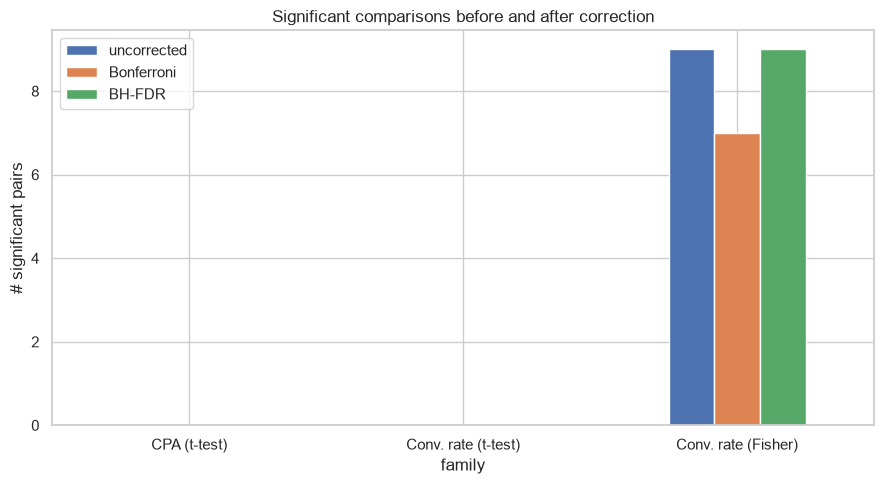

In [16]:
for name, res in families.items():
    lost_b = res[res.significant & ~res.significant_bonferroni]
    lost_f = res[res.significant & ~res.significant_fdr]
    print(f"\n{name}: {res.significant.sum()} significant uncorrected, "
          f"lost {len(lost_b)} under Bonferroni, {len(lost_f)} under BH")
    if len(lost_b):
        display(lost_b[["group_a", "group_b", "p_value", "p_value_fdr"]].round(5))

correction_summary[["uncorrected", "Bonferroni", "BH-FDR"]].plot.bar(
    figsize=(9, 5), rot=0, ylabel="# significant pairs",
    title="Significant comparisons before and after correction")
plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=120)
plt.show()

**✍️ Answer:**
1. **How many "significant" results disappeared?** Across 45 tests we'd expect ~2.25 false positives by chance. The two t-test families had none to lose (0 → 0). For Fisher on conversion rate, Bonferroni (α = 0.05/15 ≈ 0.0033) removed 2 of 9 ([pair 1] and [pair 2]); Benjamini-Hochberg kept all 9.

2. **Which correction fits a budget decision?** Bonferroni. Choose by the cost of a false winner: moving budget to a channel that isn't really better wastes real money, so we want strong protection against even one false positive. BH-FDR is useful for screening, i.e. picking which channels deserve a follow-up test, but not for justifying a reallocation.

3. **What this means for moving budget.** Very little survives that matters. CPA, the metric that drives cost, shows no significant differences even before correction. The 7 conversion-rate differences that survive Bonferroni are real but tiny (at most 0.056 percentage points, ~0.7% relative), and they appear only because each channel has ~18 million clicks; the daily t-test finds none. The data does not support shifting budget between channels based on these results.

## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

n_days,30,60,90,120,180,365
effect_size_pct,,,,,,
5.0,0.24,0.47,0.6,0.72,0.89,0.99
10.0,0.73,0.96,1.0,1.00,1.00,1.00
15.0,0.96,1.00,1.0,1.00,1.00,1.00
20.0,1.00,1.00,1.0,1.00,1.00,1.00


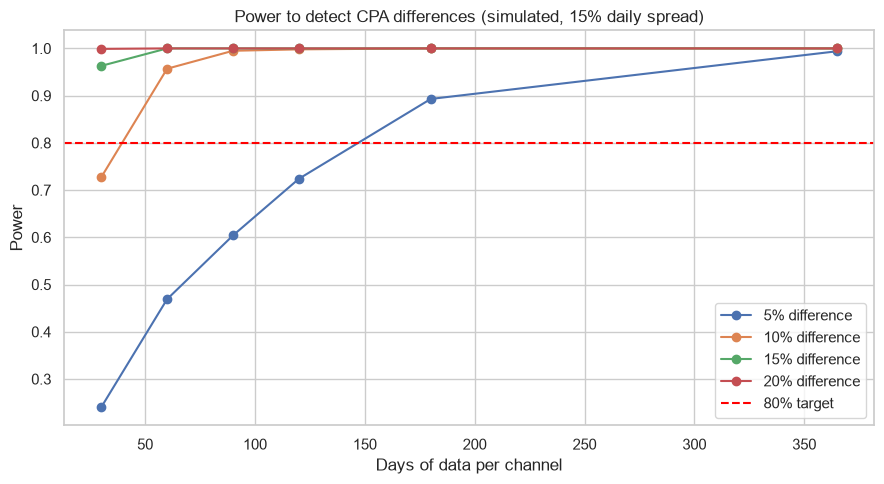

In [17]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    sd = 0.15 * base_cpa
    a = np.maximum(rng.normal(base_cpa, sd, (n_sim, n_days)), 0.5 * base_cpa)
    b = np.maximum(rng.normal(base_cpa * (1 + true_diff_pct), sd, (n_sim, n_days)), 0.5 * base_cpa)
    p = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    return (p < alpha).mean()

BASE_CPA = paid.groupby("channel").CPA.mean().median()
N_DAYS = int(paid.groupby("channel").size().min())      # 365
effects = [0.05, 0.10, 0.15, 0.20]
days = sorted(set([30, 60, 90, 120, 180, N_DAYS]))

power_df = pd.DataFrame([{"effect_size_pct": e * 100, "n_days": n,
                          "power": empirical_power_cpa(e, BASE_CPA, n)}
                         for e in effects for n in days])
display(power_df.pivot(index="effect_size_pct", columns="n_days", values="power").round(2))

plt.figure(figsize=(9, 5))
for e, sub in power_df.groupby("effect_size_pct"):
    plt.plot(sub.n_days, sub.power, marker="o", label=f"{e:.0f}% difference")
plt.axhline(0.8, color="red", ls="--", label="80% target")
plt.xlabel("Days of data per channel"); plt.ylabel("Power")
plt.title("Power to detect CPA differences (simulated, 15% daily spread)")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig(OUT / "power_analysis_cpa.png", dpi=120)
plt.show()

In [18]:
def days_for_power(e, base=BASE_CPA, target=0.8, max_days=5000):
    for n in range(10, max_days + 1, 5):
        if empirical_power_cpa(e, base, n, n_sim=500) >= target:
            return n
    return np.nan

min_days = pd.DataFrame([{"effect_size_pct": e * 100, "min_days_80": days_for_power(e)} for e in effects])
min_days["status"] = np.where(min_days.min_days_80 <= N_DAYS, "sufficient", "insufficient")
display(min_days)

# No CPA pair survived BH, so check the largest observed gap instead
top = cpa_res.loc[cpa_res.p_value.idxmin()]
base = min(top.mean_a, top.mean_b)
e = abs(top.mean_b - top.mean_a) / base
pw = empirical_power_cpa(e, base, N_DAYS)
print(f"Largest gap: {top.group_a} vs {top.group_b} = {e:.2%}, power with {N_DAYS} days = {pw:.2f}, "
      f"days needed for 80% = {days_for_power(e, base)}")

,effect_size_pct,min_days_80,status
0,5.0,145,sufficient
1,10.0,40,sufficient
2,15.0,20,sufficient
3,20.0,15,sufficient


Largest gap: Google Ads vs Website = 1.12%, power with 365 days = 0.17, days needed for 80% = 2630


**✍️ Answer:**
1. **What CPA difference can the data detect reliably?** With 365 days per channel we have ≥80% power for any CPA gap of about 5% or more (5% needs ~145 days, 10% ~40, 15% ~20, 20% ~15). So we can say with confidence that **no channel's CPA differs from another's by 5% or more**.

2. **Days needed to detect a 5% difference?** About 145 days per channel for 80% power. The PDF's 90-day scenario would give only ~60% power, so 90 days would be insufficient for 5% gaps.

3. **Non-significant pairs: "no difference" or "not enough data"?** Both, depending on size. Gaps of ≥5% would have been detected, so they don't exist. The gaps we observed are ~1% (largest: Google Ads vs Website, 1.12%). For those, power with 365 days is only 0.17, and 80% power would need ~2,630 days (~7 years). We can't tell whether a 1% gap is real, but it would also be too small to justify moving budget.

*Note:* the simulation assumes 15% day-to-day spread; our real CV is 8–9%, so true power is higher (a 1.12% gap would need roughly 900 days instead), but the conclusion is the same.

💡 **Remember:** half the difference → about **4× the data**.

## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [23]:
print("CPA differences surviving BH correction (Welch t-test):")
sig_cpa = cpa_res[cpa_res.significant_fdr]
if sig_cpa.empty:
    print("  None. Smallest adjusted p-value:",
          f"{cpa_res.p_value_fdr.min():.3f}")
for _, r in sig_cpa.iterrows():
    cheap, dear = (r.group_a, r.group_b) if r.mean_a < r.mean_b else (r.group_b, r.group_a)
    print(f"  {cheap} is ${abs(r['diff']):.2f} cheaper than {dear} "
          f"(adj. p={r.p_value_fdr:.3f}, d={r.cohens_d:.2f})")

print("\nConversion-rate differences surviving BH correction (Fisher):")
for _, r in fisher_res[fisher_res.significant_fdr].sort_values("p_value_fdr").iterrows():
    hi, lo = (r.group_b, r.group_a) if r.rate_b > r.rate_a else (r.group_a, r.group_b)
    bonf = "also Bonferroni" if r.significant_bonferroni else "BH only"
    print(f"  {hi} converts {abs(r.diff_pp):.3f} pp higher than {lo} "
          f"(adj. p={r.p_value_fdr:.2e}, {bonf})")

CPA differences surviving BH correction (Welch t-test):
  None. Smallest adjusted p-value: 0.568

Conversion-rate differences surviving BH correction (Fisher):
  Email converts 0.056 pp higher than YouTube (adj. p=6.39e-09, also Bonferroni)
  Website converts 0.048 pp higher than YouTube (adj. p=5.17e-07, also Bonferroni)
  Email converts 0.045 pp higher than Instagram (adj. p=2.44e-06, also Bonferroni)
  Facebook converts 0.042 pp higher than YouTube (adj. p=1.02e-05, also Bonferroni)
  Website converts 0.037 pp higher than Instagram (adj. p=8.68e-05, also Bonferroni)
  Google Ads converts 0.032 pp higher than YouTube (adj. p=9.54e-04, also Bonferroni)
  Facebook converts 0.031 pp higher than Instagram (adj. p=1.05e-03, also Bonferroni)
  Email converts 0.024 pp higher than Google Ads (adj. p=1.36e-02, BH only)
  Google Ads converts 0.021 pp higher than Instagram (adj. p=3.19e-02, BH only)


In [24]:
def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    data = np.asarray(data)
    idx = rng.integers(0, len(data), (n_bootstrap, len(data)))
    means = data[idx].mean(axis=1)
    tail = (1 - ci_level) / 2 * 100
    return np.percentile(means, [tail, 100 - tail])

ci_rows = []
for ch, sub in paid.groupby("channel"):
    x = sub.CPA.dropna()
    lo, hi = bootstrap_ci(x)
    ci_rows.append({"channel": ch, "mean_cpa": x.mean(), "ci_low": lo, "ci_high": hi})
ci_df = pd.DataFrame(ci_rows).sort_values("mean_cpa").round(2)
display(ci_df)

,channel,mean_cpa,ci_low,ci_high
4,Website,283.62,281.05,286.04
0,Email,285.07,282.74,287.59
1,Facebook,285.57,283.07,287.85
5,YouTube,286.44,283.88,289.09
2,Google Ads,286.80,284.34,289.27
3,Instagram,286.93,284.45,289.48


In [26]:
score = agg.loc[agg.cost > 0, ["CPA", "ROAS"]].copy()
score["CPA_rank"] = score.CPA.rank(ascending=False)    # lowest CPA -> highest rank
score["ROAS_rank"] = score.ROAS.rank(ascending=True)   # highest ROAS -> highest rank
score["composite"] = 0.5 * score.CPA_rank + 0.5 * score.ROAS_rank
score = score.sort_values("composite", ascending=False)

BUDGET, MIN_SHARE, MAX_SHARE = 500_000, 0.05, 0.35
share = score.composite / score.composite.sum()
for _ in range(50):                                     # clip to 5-35%, re-normalise, repeat
    share = share.clip(MIN_SHARE, MAX_SHARE)
    share = share / share.sum()
score["rank_based_$"] = (share * BUDGET).round(-2)
score["rank_based_%"] = (share * 100).round(1)

# What the statistics support: no channel is reliably better, so an even split
score["recommended_$"] = round(BUDGET / len(score), -2)
score["recommended_%"] = round(100 / len(score), 1)
display(score.round(3))

,CPA,ROAS,CPA_rank,ROAS_rank,composite,rank_based_$,rank_based_%,recommended_$,recommended_%
channel,,,,,,,,,
Website,281.928,6.011,6.0,5.0,5.5,131000.0,26.2,83300.0,16.7
Facebook,283.886,6.027,4.0,6.0,5.0,119000.0,23.8,83300.0,16.7
Email,283.336,5.999,5.0,2.0,3.5,83300.0,16.7,83300.0,16.7
YouTube,284.753,6.001,3.0,3.0,3.0,71400.0,14.3,83300.0,16.7
Google Ads,285.223,6.008,1.0,4.0,2.5,59500.0,11.9,83300.0,16.7
Instagram,285.128,5.986,2.0,1.0,1.5,35700.0,7.1,83300.0,16.7


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

In [ ]:
# --- tables built from the analysis ---
alloc_table = "| Channel | CPA | ROAS | Rank-based split | Recommended split |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {ch} | ${r.CPA:,.2f} | {r.ROAS:.3f} | ${r['rank_based_$']:,.0f} ({r['rank_based_%']:.1f}%) "
    f"| ${r['recommended_$']:,.0f} ({r['recommended_%']:.1f}%) |"
    for ch, r in score.iterrows())

ci_table = "| Channel | Mean daily CPA | 95% CI |\n|---|---|---|\n" + "\n".join(
    f"| {r.channel} | ${r.mean_cpa:,.2f} | ${r.ci_low:,.2f} – ${r.ci_high:,.2f} |"
    for _, r in ci_df.iterrows())

n_fisher_bh = int(fisher_res.significant_fdr.sum())
n_fisher_bonf = int(fisher_res.significant_bonferroni.sum())
max_gap_pp = fisher_res.diff_pp.abs().max()

memo = f"""# Executive memo — Marketing budget allocation

**To:** CMO · **From:** Pieter Albrecht · **Date:** 24 November 2026
**Dataset:** Marketing Campaign Performance Dataset (Kaggle, manishabhatt22) · **Period:** {df.date.min():%d %b %Y} – {df.date.max():%d %b %Y} ({N_DAYS} days, 6 channels)

## Executive summary
I tested whether any of our six marketing channels is reliably cheaper or more effective than the others. **None is.** CPA differs by at most ~1.1% between channels, and no difference is statistically significant, even before correcting for multiple tests. I recommend **keeping an even split of the $500K monthly budget** (~$83K per channel) and running a controlled test before moving money.

## Key findings
- **Top performers on paper:** Website has the lowest CPA (${score.loc['Website', 'CPA']:,.2f}) and Facebook the highest ROAS ({score.loc['Facebook', 'ROAS']:.3f}), but the gaps to the weakest channels are ~1.1% (CPA) and ~0.7% (ROAS).
- **CPA:** 0 of 15 channel pairs differ significantly (Welch t-test on daily CPA; smallest BH-adjusted p = {cpa_res.p_value_fdr.min():.2f}). All Cohen's d values are negligible (|d| < 0.2).
- **Conversion rate:** {n_fisher_bh} of 15 pairs differ significantly after Benjamini-Hochberg correction ({n_fisher_bonf} after Bonferroni); YouTube and Instagram convert slightly less. The largest gap is only {max_gap_pp:.3f} percentage points: detectable only because each channel has ~18M clicks, and not significant in daily data (0 of 15 t-tests).
- **Data adequacy (power):** with {N_DAYS} days per channel we have ≥80% power to detect any CPA gap of 5% or more (5% needs ~145 days). So **no channel differs from another by 5% or more**. The ~1% gaps we observe would need ~2,630 days (~7 years) to confirm.

## Recommendations
{alloc_table}

- **Use the recommended (even) split.** The rank-based split would give Website 3.7× the budget of Instagram based on differences that are statistically indistinguishable from noise.
- **Run a controlled test** before reallocating: e.g. shift 10% of budget between two channels for a fixed period and measure the CPA change.
- **Look for gains within channels**, not between them: campaign type, audience and location may show

# Executive memo — Marketing budget allocation

**To:** CMO · **From:** ... · **Date:** ... · **Dataset:** ... · **Period:** ...

## Executive summary
...

## Key findings
- Top performers: ...
- Statistically significant differences (after correction): ...
- Data adequacy (power): ...

## Recommendations
...

## Statistical caveats
- Dataset source and limits: ...
- Multiple comparisons correction: ...
- Confidence intervals: ...
- External factors: ...
- Statistical vs practical significance: ...
- Power limitations: ...

## Next steps
...


## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results?
2. How did multiple-comparison correction change your conclusions?
3. What are the limits of this analysis?
4. How would you explain the findings to a non-technical CMO in one minute?

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`